In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
iris = load_iris()
X = iris.data
y = iris.target

In [ ]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y

print("First five rows of dataset:")
print(df.head())

print("\nTarget Classes:")
print(iris.target_names)

First five rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Target Classes:
['setosa' 'versicolor' 'virginica']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
kernels = ["linear", "poly", "rbf", "sigmoid"]

results = []

In [ ]:
for kernel in kernels:
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Kernel": kernel,
        "Accuracy": accuracy
    })

    print("\n-----------------------------------")
    print("Kernel:", kernel)
    print("Accuracy:", accuracy)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))


-----------------------------------
Kernel: linear
Accuracy: 1.0
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


-----------------------------------
Kernel: poly
Accuracy: 0.9
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  3  7]]
Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.77      1.00      0.87        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighte


Accuracy Comparison:
    Kernel  Accuracy
0   linear  1.000000
1     poly  0.900000
2      rbf  0.966667
3  sigmoid  0.900000


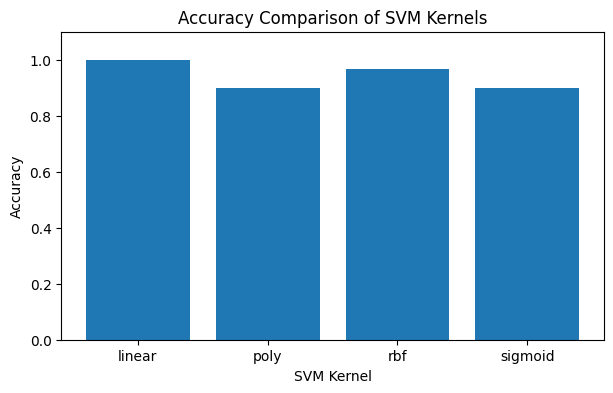

In [ ]:
results_df = pd.DataFrame(results)

print("\nAccuracy Comparison:")
print(results_df)

# 8. Plot accuracy comparison
plt.figure(figsize=(7, 4))
plt.bar(results_df["Kernel"], results_df["Accuracy"])
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of SVM Kernels")
plt.ylim(0, 1.1)
plt.show()